# Phase 05 — Manifest v3 Promotion & Leakage Closure

**Phase ID:** `phase_05_leakage_audit`  
**Notebook:** Part 1E — Final Canonical Promotion (governance closure)  
**Model:** Gemini 3.1 Pro High  
**Project Root:** `D:\Softfors\jup`  
**Kernel:** `jup-venv`  

---

This notebook **formally promotes** the independently-audited `phase4_v3` candidate manifest to canonical active-development governance and **closes Phase 05**.

**Scope of this notebook (strictly limited):**
- No model training.
- No model inference.
- No Phase 06 scientific analysis.
- No modification of TEST membership.
- **Zero** reads of TEST image or mask *content*.
- No overwriting of historical `phase4_v2` manifests.

This is a **governance / provenance** closure notebook, not a re-analysis.

In [1]:
# Environment & provenance banner
import hashlib
import json
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
FIG_DIR = PROJECT_ROOT / 'reports' / 'figures' / 'phase05_leakage_audit' / 'closure'

print('python        :', sys.version.split()[0])
print('platform      :', platform.platform())
print('pandas        :', pd.__version__)
print('numpy         :', np.__version__)
print('project root  :', PROJECT_ROOT)
print('generated_at  :', datetime.now(timezone.utc).isoformat())

# Governance counters enforced throughout this notebook
GOVERNANCE = {
    'test_image_reads': 0,
    'test_mask_reads': 0,
    'test_decodes': 0,
    'test_visualizations': 0,
    'test_metrics': 0,
    'training_runs': 0,
    'inference_runs': 0,
    'manifest_writes_to_v2': 0,
}

python        : 3.11.9
platform      : Windows-10-10.0.26200-SP0
pandas        : 3.0.5
numpy         : 2.4.6
project root  : D:\Softfors\jup
generated_at  : 2026-09-19T19:21:21.360172+00:00


In [2]:
# Canonical hash helpers + all expected hashes from the promotion brief
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

CANDIDATE_DIR = PROJECT_ROOT / 'manifests' / 'phase4_v3_candidate'
V3_DIR = PROJECT_ROOT / 'manifests' / 'phase4_v3'
V2_DIR = PROJECT_ROOT / 'manifests'

CANDIDATE_FILES = {
    'all_paired':         'all_paired_v3_candidate.csv',
    'train':              'train_v3_candidate.csv',
    'val':                'val_v3_candidate.csv',
    'test':               'test_v3_candidate.csv',
    'quarantined':        'quarantined_v3_candidate.csv',
    'duplicate_groups':   'duplicate_groups_v3_candidate.csv',
    'grouping_provenance':'grouping_provenance_v3_candidate.csv',
}
PROMOTED_FILES = {k: f'{k}.csv' for k in CANDIDATE_FILES}

EXPECTED_V3 = {
    'all_paired':          'eb3062fa0e84f9952f994df79ed4d767417a912e18dce86560f6e2edcdd02ded',
    'train':               '28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6',
    'val':                 '082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315',
    'test':                '9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727',
    'quarantined':         'a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c',
    'duplicate_groups':    '830d3c0ce08f735081e5a44fe3a740031da1c70cfc19ebcb4ef89c31acd704fb',
    'grouping_provenance': '3eff84851d33e1c8b5894ce05049433287067a5e6088a90f5c67394230317f66',
}
EXPECTED_V2 = {
    'all_paired': '66350d465209e4bf0948a16f0da213abb9f8f87c0b222ead7632d2350463f7cc',
    'train':      'd67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb33188355cfa6056bc3',
    'val':        '46079b594ed9535c2de953bb976684b8b0bab30c27c6e6e4f2b9f9314b4cc5f4',
    'test':       '9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727',
}
EXPECTED_TEST_SHA = '9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727'
EXPECTED_BUSI_MAPPING_SHA = 'df4b01487ea6e1cb5c004e11535e4c3252c19dc3b84cbb21816c737dbaf2753b'
EXPECTED_BUSI_SOURCE_SHA = '14f6bb5332036218e4c59d119d12ea67281b0a4d1373668d35530763f9121d44'

print('Expected hash tables configured:', len(EXPECTED_V3), 'v3 files,', len(EXPECTED_V2), 'v2 files')
print('TEST hard gate SHA:', EXPECTED_TEST_SHA)

Expected hash tables configured: 7 v3 files, 4 v2 files
TEST hard gate SHA: 9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727


## 2. Why Phase 05 Discovered a Governance Defect

Phase 04 produced a *structurally valid* canonical split: sample IDs were disjoint, counts reconciled, and the manifest reproducible. **But structural validity is not the same as leakage safety.**

Phase 05 began as a forensic leakage audit and surfaced a **governance defect**, not merely a data defect:

1. **The split was treated as clean because it was canonical.** Canonicalisation froze membership before any rigorous cross-split duplicate / patient-overlap adjudication had been performed. Governance inherited an unverified assumption.
2. **Cross-split leakage mechanisms existed that disjointness checks could not catch** — exact image content collisions, patient-group overlap across datasets, same-acquisition near-duplicates, and TEST-linked pHash high-risk pairs.
3. **No version-aware manifest contract existed.** Code loaded a single ambiguous `manifests/train.csv`. There was no way to distinguish a historical split from a remediated one, nor to prevent new work from silently inheriting contaminated membership.
4. **Remediation could not be applied in place.** Modifying the frozen manifest would have destroyed the provenance required to reproduce Phases 06–15.

**Conclusion:** the correct remedy was a *versioned* manifest — keep v2 frozen as historical provenance, construct and audit a leakage-safe v3, and promote v3 as the explicit canonical active-development version.

## 3. v2 Historical Provenance (immutable)

`phase4_v2` is the original canonical-era split. It is **not invalid evidence** — it is the *exact* membership required to reproduce historical Phases 06–15. It must never be modified or deleted.

In [3]:
# Verify v2 root manifests are present and hash-exact (immutability evidence)
v2_rows = []
for key, expected in EXPECTED_V2.items():
    p = V2_DIR / f'{key}.csv'
    actual = sha256_file(p)
    v2_rows.append({
        'file': f'manifests/{key}.csv',
        'exists': p.exists(),
        'expected_sha256': expected,
        'actual_sha256': actual,
        'match': actual == expected,
    })
v2_df = pd.DataFrame(v2_rows)
display(v2_df)
V2_HASHES_UNCHANGED = bool(v2_df['match'].all())
print('v2 HASHES UNCHANGED:', V2_HASHES_UNCHANGED)

,file,exists,expected_sha256,actual_sha256,match
0,manifests/all_paired.csv,True,66350d465209e4bf0948a16f0da213abb9f8f87c0b222e...,66350d465209e4bf0948a16f0da213abb9f8f87c0b222e...,True
1,manifests/train.csv,True,d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb...,d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb...,True
2,manifests/val.csv,True,46079b594ed9535c2de953bb976684b8b0bab30c27c6e6...,46079b594ed9535c2de953bb976684b8b0bab30c27c6e6...,True
3,manifests/test.csv,True,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...,True


v2 HASHES UNCHANGED: True


## 4. Evidence Requiring Remediation

The following findings (established in Parts 1A–1D) required a leakage-safe rebuild:

| # | Mechanism | Finding | Treatment |
|---|---|---|---|
| 1 | KUB exact image duplicate | TRAIN/VAL cross-split raw asset collision (`00273-01` <-> `00320-01`) | 1 exact duplicate quarantined |
| 2 | BUSI patient-group overlap | BUSI lacked usable patient group IDs; overlap undetected | Patient groups recovered; 5 overlap cases quarantined |
| 3 | ISIC d0 same-acquisition | 13 likely same-acquisition pairs at pHash distance 0 | 13 quarantined (SAME_ACQUISITION) |
| 4 | TRAIN<->VAL d2 conservative | 3 unresolved conservative high-risk groups | 3 quarantined (CONSERVATIVE_HIGH_RISK_GROUPING) |
| 5 | TEST-linked patient overlap | 62 development samples sharing patients with locked TEST | 62 quarantined |
| 6 | TEST-linked pHash high-risk | 34 development samples with d<=2 pHash proximity to TEST | 34 quarantined |

Historical TEST-linked evidence is drawn from the **frozen pre-lock** audit records (`reports/audits/leakage_audit.json`, `reports/audits/near_duplicate_candidates.csv`). **No TEST image or mask content was read during remediation.**

In [4]:
# Summarise the evidence that drove remediation
q = pd.read_csv(V3_DIR / 'quarantined.csv')
reason_counts = q['quarantine_reason'].value_counts()
display(pd.DataFrame({'quarantine_reason': reason_counts.index,
                      'count': reason_counts.values}))
print('Total quarantined:', int(reason_counts.sum()))

# Split-level provenance of quarantined samples
print()
print('Quarantined by original v2 split:')
print(q['split_v2'].value_counts().to_string())

,quarantine_reason,count
0,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,62
1,QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK,34
2,QUARANTINED_SAME_ACQUISITION,13
3,QUARANTINED_BUSI_PATIENT_OVERLAP,5
4,CONSERVATIVE_HIGH_RISK_GROUPING,3
5,QUARANTINED_EXACT_DUPLICATE,1


Total quarantined: 118

Quarantined by original v2 split:
split_v2
TRAIN    81
VAL      37


## 5. v3 Remediation Principles

The v3 rebuild followed six governing principles:

1. **Conservative quarantine over optimistic retention.** Where leak risk was unresolved, the sample was quarantined rather than kept.
2. **Development-side only.** Remediation removed samples from TRAIN/VAL only. TEST membership was treated as immutable.
3. **Provenance conservation.** Every original sample remains accounted for exactly once across `{TRAIN, VAL, TEST, QUARANTINED}`; total stays 8441.
4. **Group-aware splitting.** Patient/group identity was enforced before split assignment, not after.
5. **Byte-for-byte promotion.** The audited candidate is promoted verbatim — no recomputation, no silent edits.
6. **Explicit versioning.** v2 and v3 are distinguished by path and by a version-aware manifest guard so old scripts cannot silently reinterpret their input.

## 6. Final v3 Population

In [5]:
# Count actual rows in the promoted v3 manifests
v3_counts = {}
for key in ('train', 'val', 'test', 'quarantined'):
    df = pd.read_csv(V3_DIR / f'{key}.csv')
    v3_counts[key.upper()] = len(df)
allp = pd.read_csv(V3_DIR / 'all_paired.csv')
v3_counts['ALL_PAIRED_ROWS'] = len(allp)

EXPECTED_COUNTS = {'TRAIN': 5832, 'VAL': 808, 'TEST': 1683, 'QUARANTINED': 118}
count_rows = []
for k, exp in EXPECTED_COUNTS.items():
    count_rows.append({'split': k, 'expected': exp, 'actual': v3_counts[k],
                       'match': v3_counts[k] == exp})
active_total = v3_counts['TRAIN'] + v3_counts['VAL'] + v3_counts['TEST']
count_rows.append({'split': 'ACTIVE_TOTAL', 'expected': 8323, 'actual': active_total,
                   'match': active_total == 8323})
count_rows.append({'split': 'TOTAL_WITH_QUARANTINE', 'expected': 8441,
                   'actual': active_total + v3_counts['QUARANTINED'],
                   'match': (active_total + v3_counts['QUARANTINED']) == 8441})
counts_df = pd.DataFrame(count_rows)
display(counts_df)
POPULATION_OK = bool(counts_df['match'].all())
print('POPULATION ACCOUNTING 8441 CONSERVED:', POPULATION_OK)

,split,expected,actual,match
0,TRAIN,5832,5832,True
1,VAL,808,808,True
2,TEST,1683,1683,True
3,QUARANTINED,118,118,True
4,ACTIVE_TOTAL,8323,8323,True
5,TOTAL_WITH_QUARANTINE,8441,8441,True


POPULATION ACCOUNTING 8441 CONSERVED: True


In [6]:
# Per-dataset breakdown of the final v3 population
q = pd.read_csv(V3_DIR / 'quarantined.csv')
rows = []
for ds in ['KUB', 'ISIC', 'BUSI', 'KVASIR']:
    tr = pd.read_csv(V3_DIR / 'train.csv')
    va = pd.read_csv(V3_DIR / 'val.csv')
    te = pd.read_csv(V3_DIR / 'test.csv')
    rows.append({
        'dataset': ds,
        'TRAIN': int((tr['dataset'] == ds).sum()),
        'VAL': int((va['dataset'] == ds).sum()),
        'TEST': int((te['dataset'] == ds).sum()),
        'QUARANTINED': int((q['dataset'] == ds).sum()),
    })
breakdown = pd.DataFrame(rows)
EXPECTED_BREAKDOWN = {
    'KUB':    {'TRAIN': 1978, 'VAL': 280, 'TEST': 558, 'QUARANTINED': 4},
    'ISIC':   {'TRAIN': 2556, 'VAL': 357, 'TEST': 735, 'QUARANTINED': 46},
    'BUSI':   {'TRAIN': 602,  'VAL': 84,  'TEST': 174, 'QUARANTINED': 67},
    'KVASIR': {'TRAIN': 696,  'VAL': 87,  'TEST': 216, 'QUARANTINED': 1},
}
ok = True
for _, r in breakdown.iterrows():
    exp = EXPECTED_BREAKDOWN[r['dataset']]
    for k, v in exp.items():
        ok = ok and int(r[k]) == v
display(breakdown)
BREAKDOWN_OK = ok
print('DATASET BREAKDOWN MATCHES BRIEF:', BREAKDOWN_OK)

,dataset,TRAIN,VAL,TEST,QUARANTINED
0,KUB,1978,280,558,4
1,ISIC,2556,357,735,46
2,BUSI,602,84,174,67
3,KVASIR,696,87,216,1


DATASET BREAKDOWN MATCHES BRIEF: True


## 7. Final Quarantine Breakdown

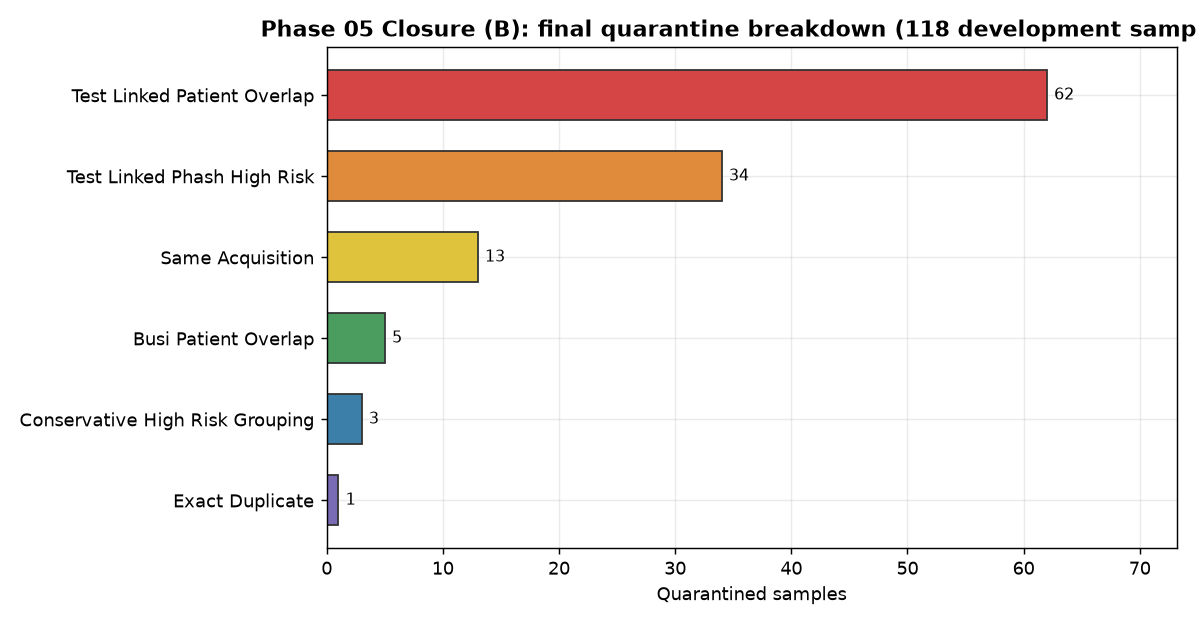

Figure B — final quarantine breakdown (118 development samples).


In [7]:
display(Image(filename=str(FIG_DIR / 'phase05_closure_quarantine_breakdown.png')))
print('Figure B — final quarantine breakdown (118 development samples).')

## 8. BUSI Recovered Patient Grouping

BUSI originally lacked canonical patient identifiers, so patient-level overlap with TEST could not be detected by the v2 audit. During Phase-05 remediation, patient groups were **recovered from the source metadata** and mapped deterministically.

The mapping artifact is hashed so the recovered grouping is reproducible.

In [8]:
busi_map_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase05_busi_patient_group_mapping.csv'
busi_sha = sha256_file(busi_map_path)
busi_df = pd.read_csv(busi_map_path)
print('BUSI mapping artifact :', busi_map_path.name)
print('BUSI mapping rows     :', len(busi_df))
print('BUSI mapping SHA      :', busi_sha)
print('expected SHA          :', EXPECTED_BUSI_MAPPING_SHA)
print('match                 :', busi_sha == EXPECTED_BUSI_MAPPING_SHA)
print('source metadata SHA   :', EXPECTED_BUSI_SOURCE_SHA)
BUSI_MAPPING_OK = busi_sha == EXPECTED_BUSI_MAPPING_SHA
display(busi_df.head(10))

BUSI mapping artifact : phase05_busi_patient_group_mapping.csv
BUSI mapping rows     : 927
BUSI mapping SHA      : df4b01487ea6e1cb5c004e11535e4c3252c19dc3b84cbb21816c737dbaf2753b
expected SHA          : df4b01487ea6e1cb5c004e11535e4c3252c19dc3b84cbb21816c737dbaf2753b
match                 : True
source metadata SHA   : 14f6bb5332036218e4c59d119d12ea67281b0a4d1373668d35530763f9121d44


,sample_id,source_case_id,original_split_v2,candidate_split_v3,active_v3,quarantine_reason,busi_patient_group_id,mapping_source,mapping_rule,mapping_status
0,8b0a07dabea0d0c0bd9b0dc96e89a628,10046-9.bmp,QUARANTINED,QUARANTINED,False,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,10046,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
1,e31790ef484d7ed9f04bc74dad7030b6,00460.bmp,TRAIN,TRAIN,True,NaN,460,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
2,2f0d944d96027b7519c79d270137ab47,00913.bmp,TRAIN,TRAIN,True,NaN,913,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
3,98bb88b56d296f62bc596b75b7159169,10064-5.bmp,QUARANTINED,QUARANTINED,False,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,10064,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
4,4d2415d916d7db270cf7f9058728487e,00704.bmp,TRAIN,TRAIN,True,NaN,704,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
5,df4c07315a7957e3ef853e7f0c6c6391,00857.bmp,TRAIN,TRAIN,True,NaN,857,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
6,40af76803b83b6a90d7e80cb1115e86c,00539.bmp,TRAIN,TRAIN,True,NaN,539,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
7,4ae488b0068c40b6513e33c723e17b1a,00106.bmp,TRAIN,TRAIN,True,NaN,106,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
8,5f8df059031702097a483e5d7e2fea7e,00268.bmp,TRAIN,TRAIN,True,NaN,268,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED
9,cbbac941b368a11e3ceaf8f4018c04bc,00813.bmp,TRAIN,TRAIN,True,NaN,813,Patient_infos_BUSI-WHU.xlsx,img_names == basename(image_path),MAPPED


## 9. KUB Exact Duplicate Resolution

A single exact raw-image asset collision was confirmed between TRAIN and VAL under v2 (`patient-00273` TRAIN vs `patient-00320` VAL). The duplicate was resolved by quarantining the development-side duplicate, yielding exactly **1** `QUARANTINED_EXACT_DUPLICATE`.

Exact-duplicate quarantined samples: 1


,dataset,task_id,sample_id,patient_id,split_v2,split
2,KUB,3,a62708e2834fab0c56d4f575f49f7c61,patient-00320,VAL,QUARANTINED


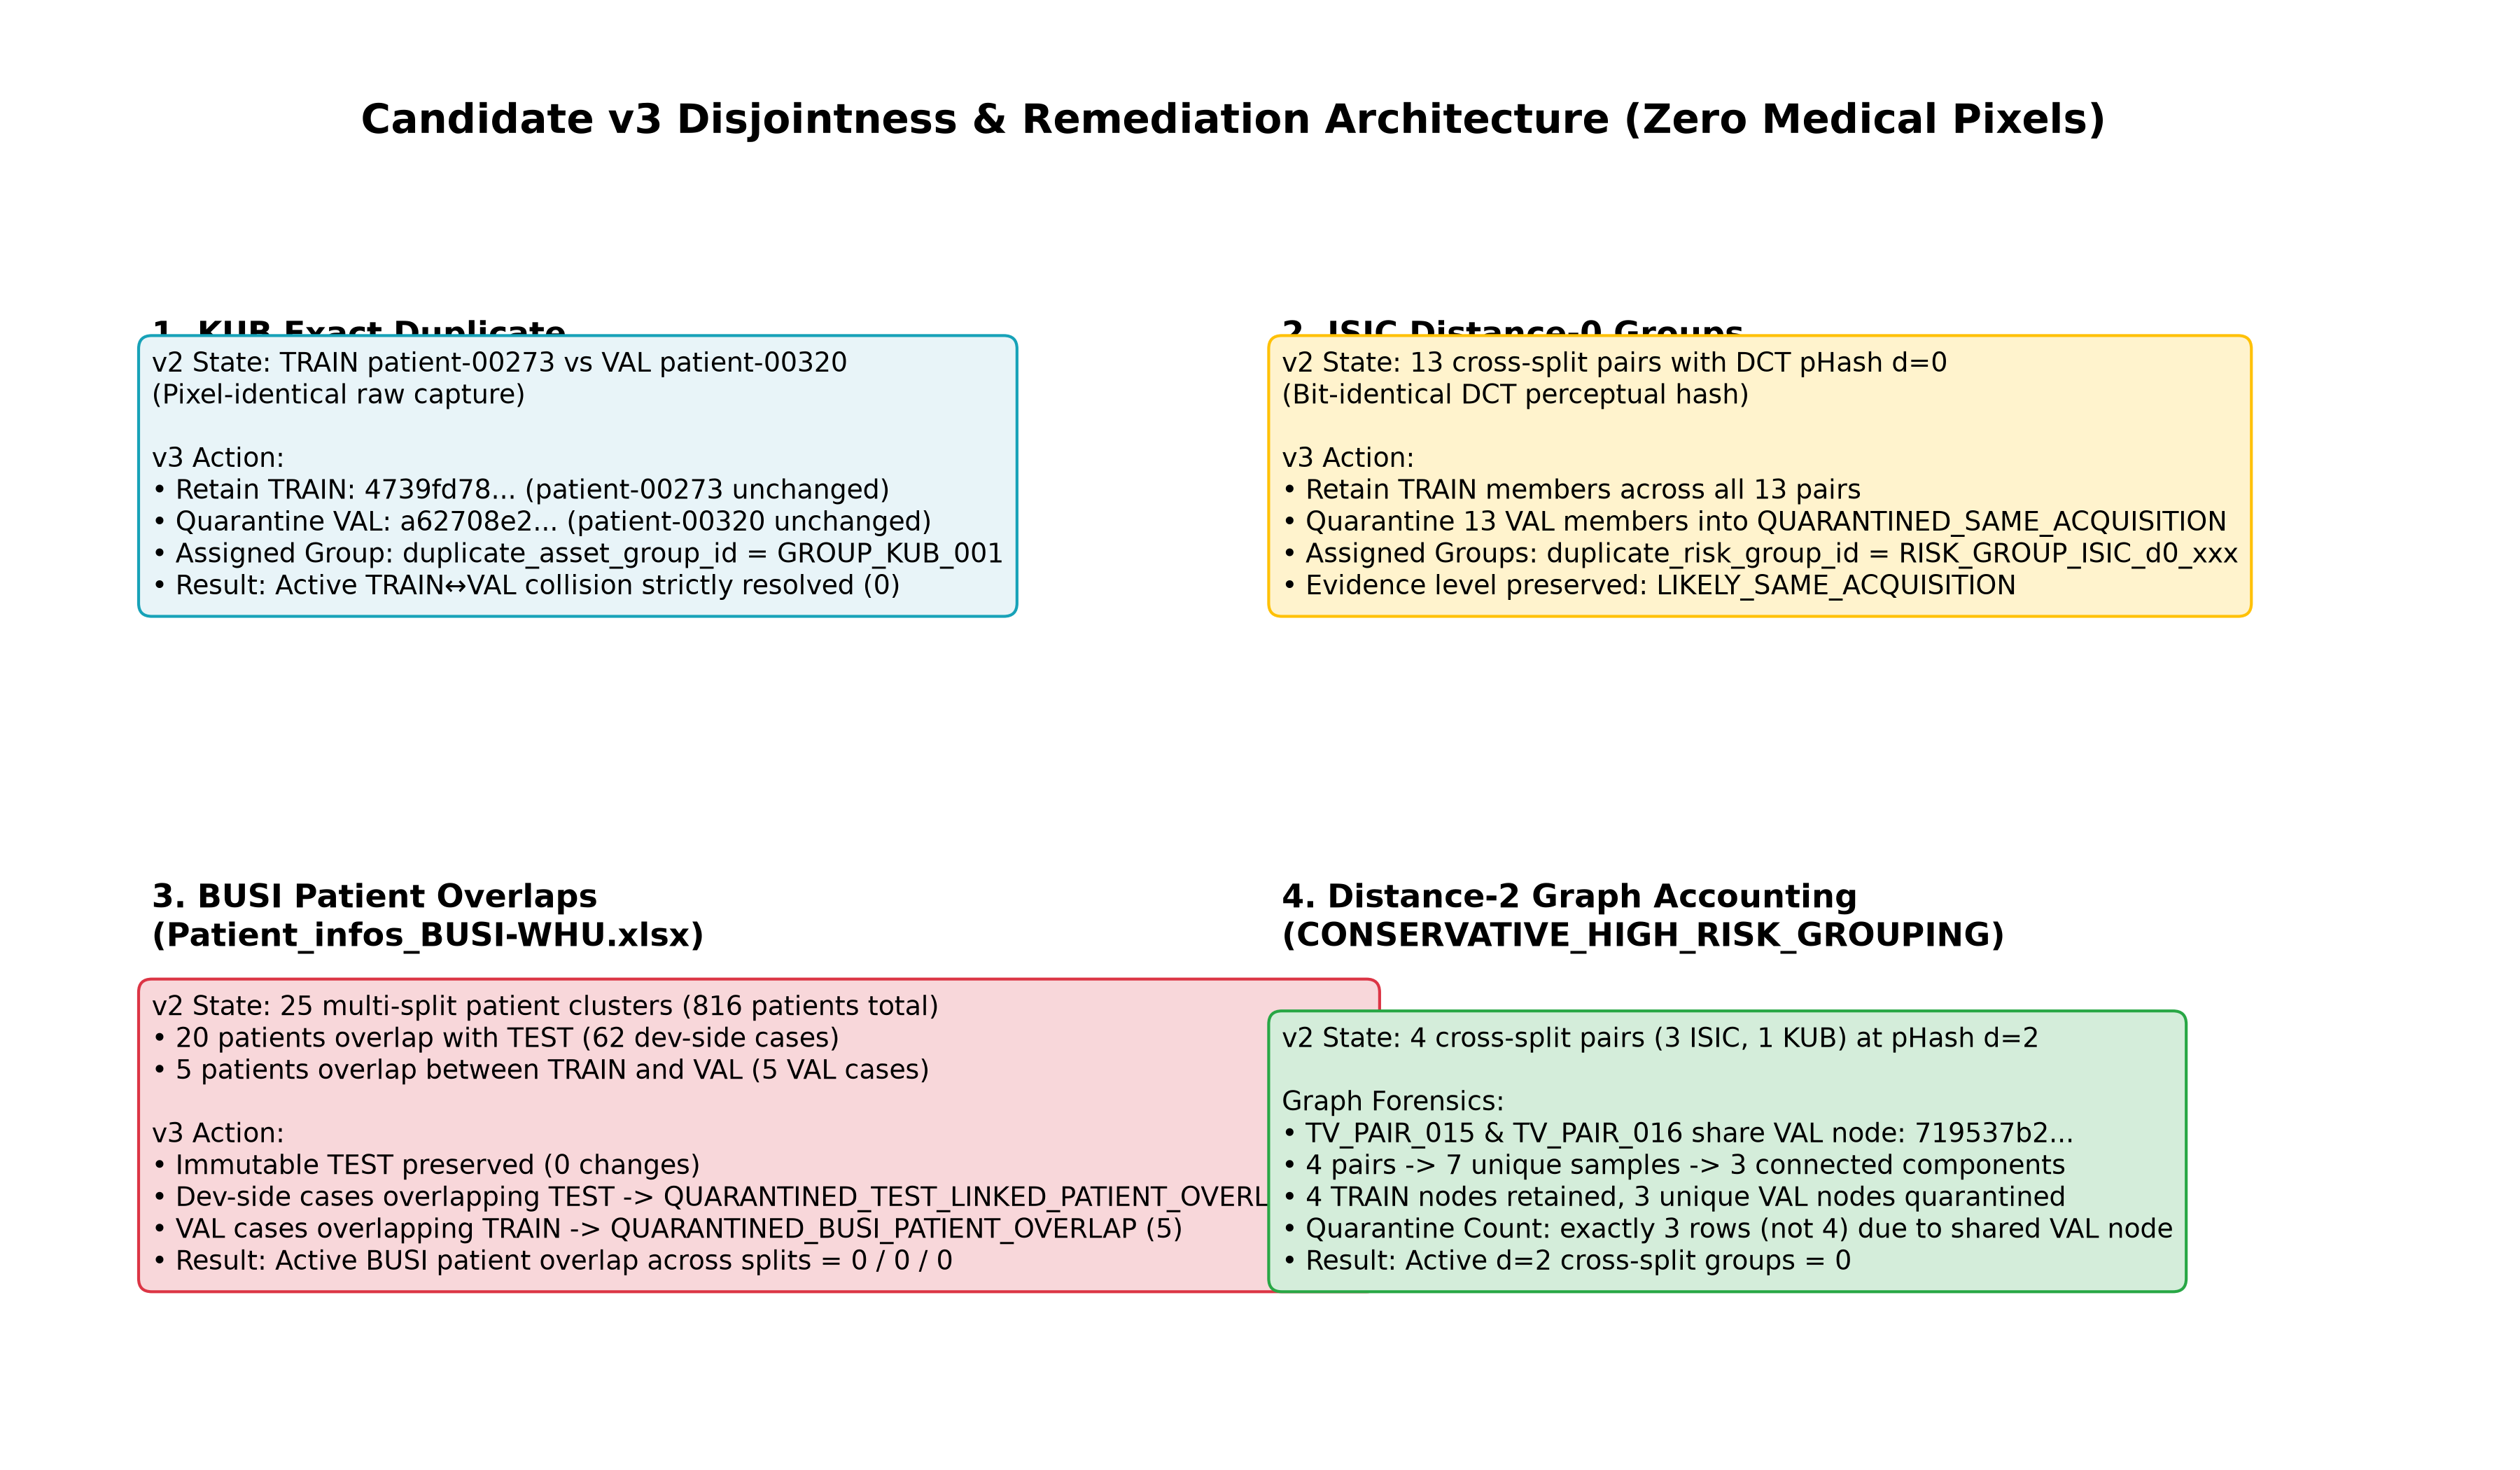

In [9]:
exact_dupes = q[q['quarantine_reason'] == 'QUARANTINED_EXACT_DUPLICATE']
print('Exact-duplicate quarantined samples:', len(exact_dupes))
cols = [c for c in ['dataset', 'task_id', 'sample_id', 'patient_id', 'split_v2', 'split'] if c in exact_dupes.columns]
display(exact_dupes[cols] if len(exact_dupes) else pd.DataFrame())

fg_path = PROJECT_ROOT / 'reports' / 'figures' / 'phase05_leakage_audit' / 'v3_candidate' / 'phase05_v3_duplicate_group_resolution.png'
if fg_path.exists():
    display(Image(filename=str(fg_path)))
KUB_EXACT_DUPLICATE_OK = len(exact_dupes) == 1

## 10. ISIC / pHash High-Risk Treatment

Perceptual-hash (pHash) analysis identified development-side samples at high near-duplicate risk. Treatment was conservative:

- **13** ISIC same-acquisition pairs at distance 0 -> quarantined.
- **3** unresolved conservative high-risk groups -> quarantined.
- **34** development samples with d<=2 proximity to TEST -> quarantined.
- **62** development samples sharing patients with locked TEST -> quarantined.

The residual, unresolved risk is explicitly acknowledged in the Phase-05 conclusion: no method can claim to eliminate *all conceivable* duplicate risk in the universe.

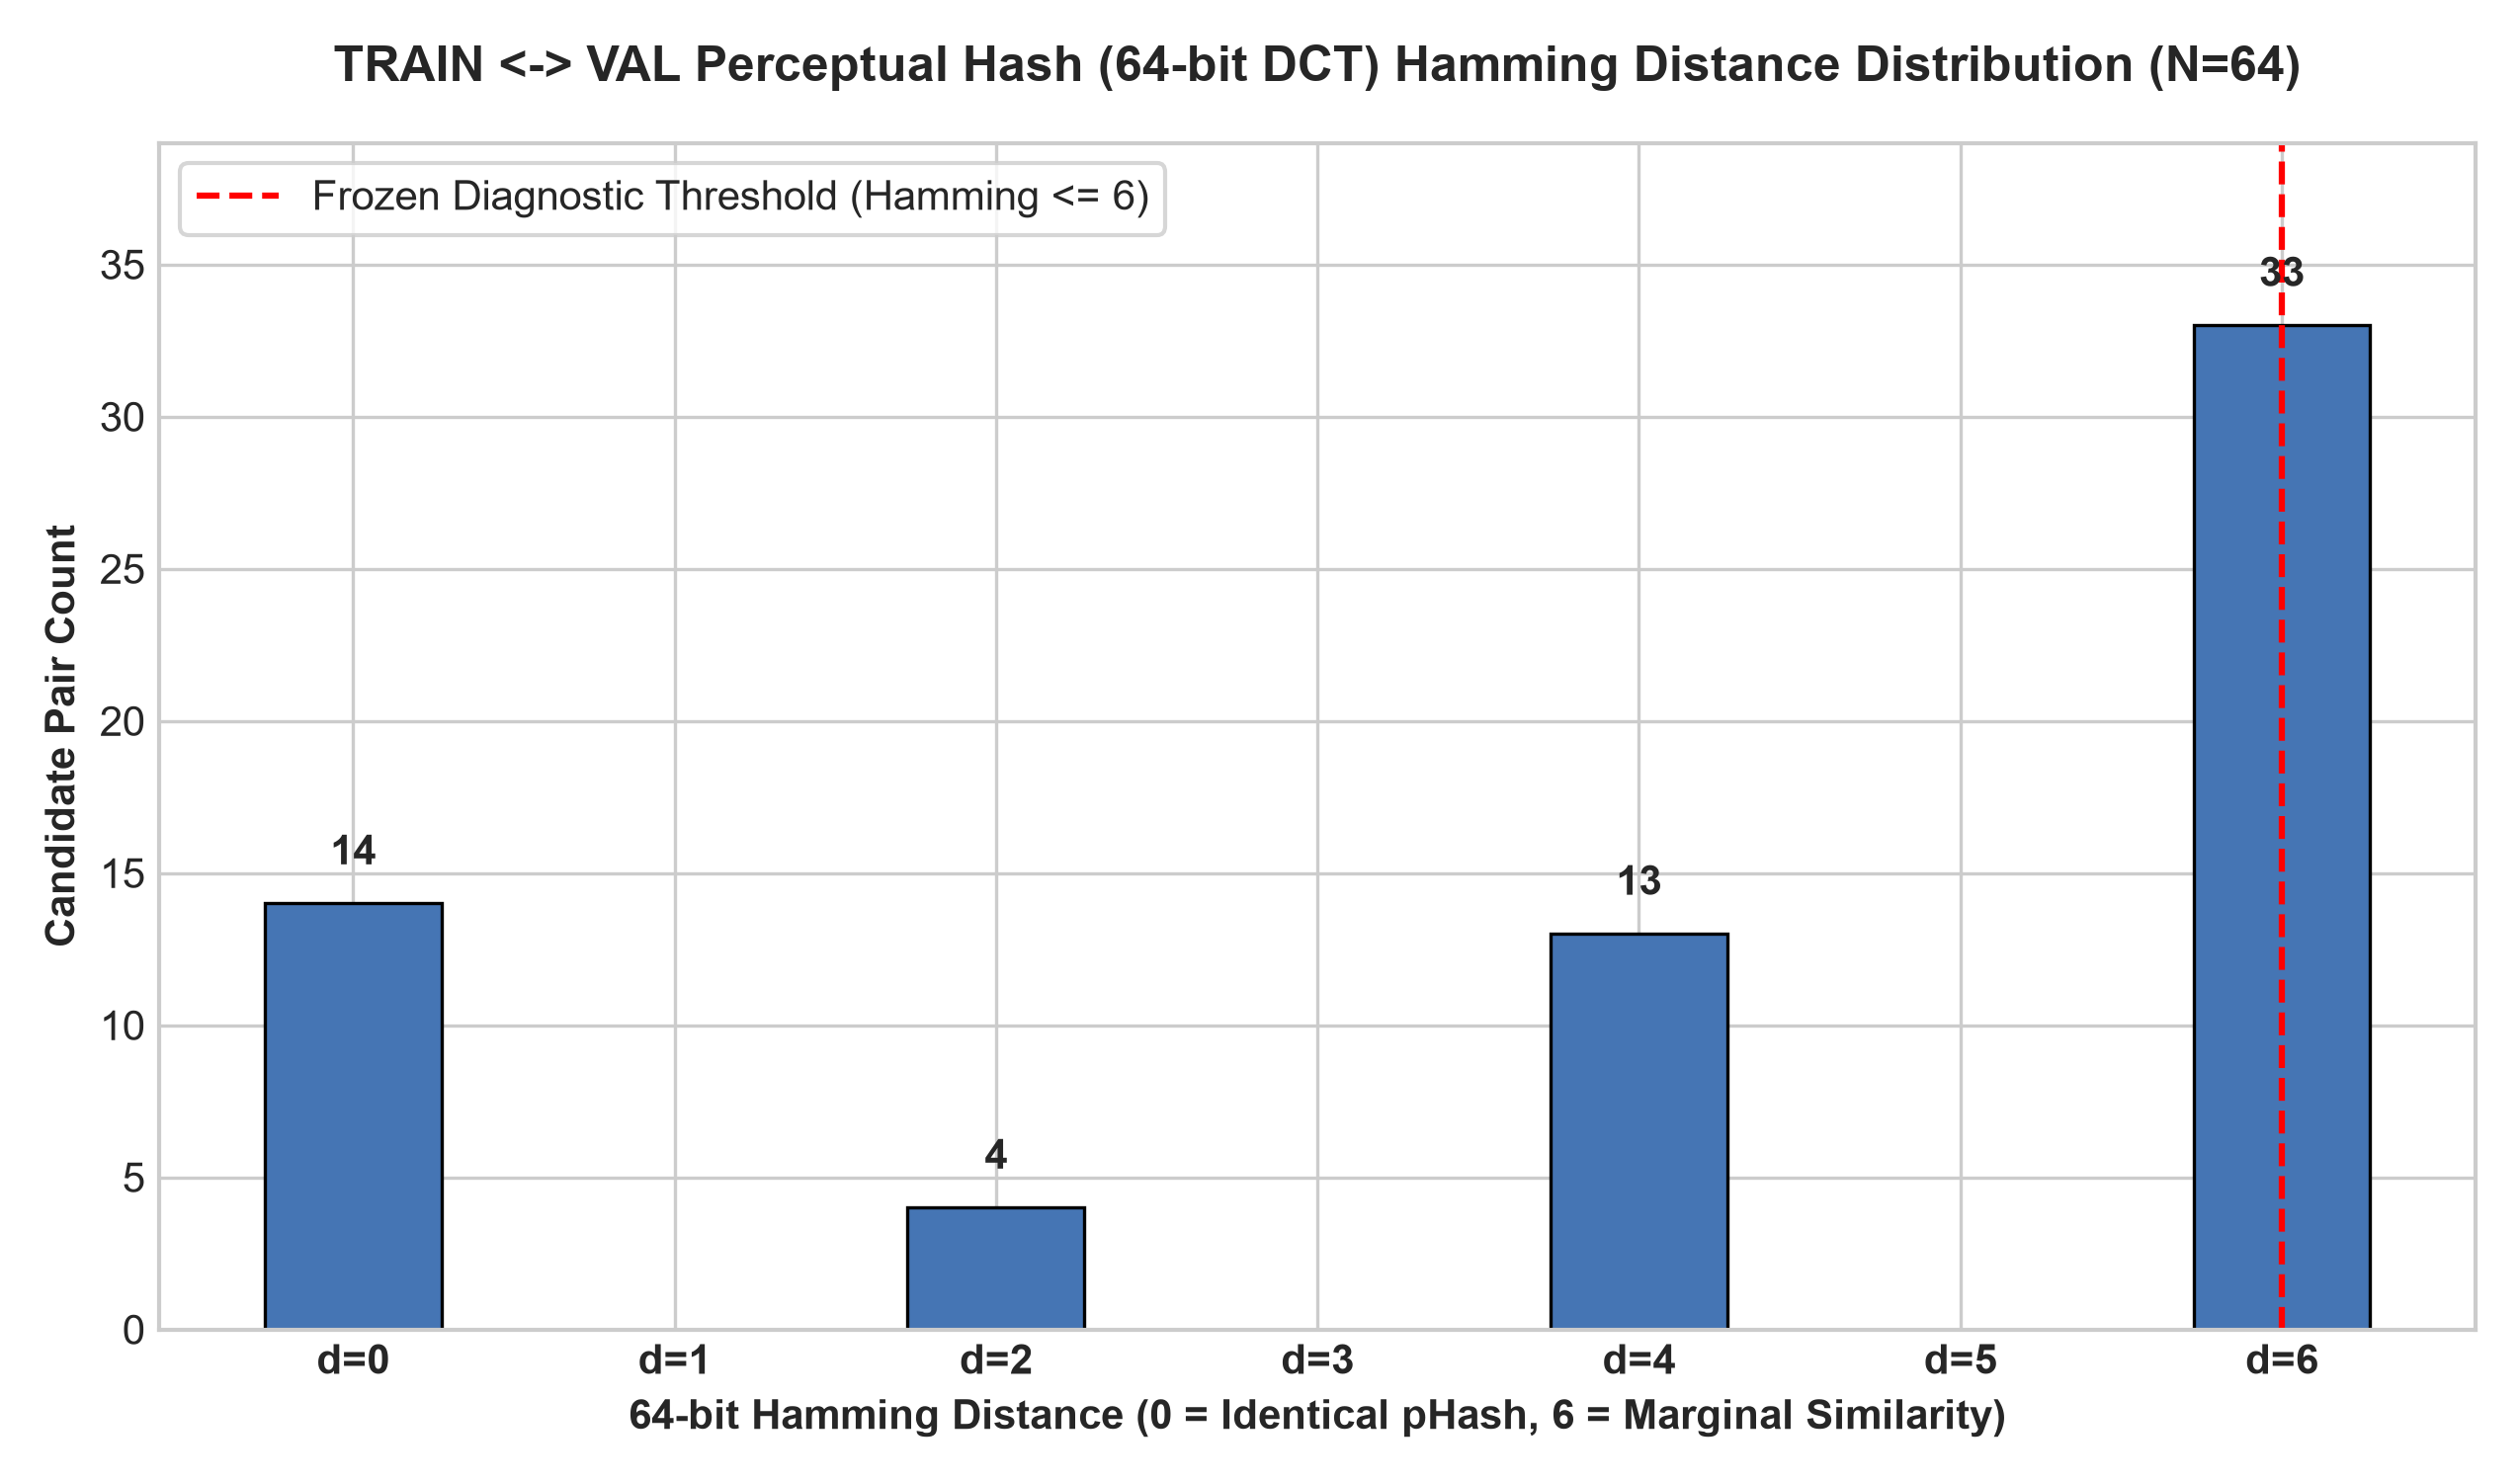

QUARANTINED_SAME_ACQUISITION                    : 13
CONSERVATIVE_HIGH_RISK_GROUPING                 : 3
QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK         : 34
QUARANTINED_TEST_LINKED_PATIENT_OVERLAP         : 62


In [10]:
phash_fig = PROJECT_ROOT / 'reports' / 'figures' / 'phase05_leakage_audit' / 'aggregate' / 'phase05_phash_distance_distribution.png'
if phash_fig.exists():
    display(Image(filename=str(phash_fig)))
for reason in ['QUARANTINED_SAME_ACQUISITION', 'CONSERVATIVE_HIGH_RISK_GROUPING',
               'QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK',
               'QUARANTINED_TEST_LINKED_PATIENT_OVERLAP']:
    print(f'{reason:48s}: {int((q["quarantine_reason"] == reason).sum())}')

## 11. TEST Invariance (hard gate)

TEST membership was **not changed**. TEST medical content was **not read, decoded, or visualised**. The promoted v3 TEST is byte-identical to the v2 TEST.

In [11]:
# Hash-only comparison: NO TEST content is read, decoded, or displayed.
v2_test_sha = sha256_file(V2_DIR / 'test.csv')
v3_test_sha = sha256_file(V3_DIR / 'test.csv')
cand_test_sha = sha256_file(CANDIDATE_DIR / 'test_v3_candidate.csv')

test_rows = [
    {'artifact': 'manifests/test.csv (v2)', 'sha256': v2_test_sha},
    {'artifact': 'manifests/phase4_v3/test.csv (v3)', 'sha256': v3_test_sha},
    {'artifact': 'candidate test_v3_candidate.csv', 'sha256': cand_test_sha},
    {'artifact': 'EXPECTED_TEST_SHA (brief)', 'sha256': EXPECTED_TEST_SHA},
]
display(pd.DataFrame(test_rows))
TEST_BYTE_IDENTICAL = (v2_test_sha == v3_test_sha == cand_test_sha == EXPECTED_TEST_SHA)
print('TEST byte-identical across v2 / v3 / candidate:', TEST_BYTE_IDENTICAL)

# Compare TEST sample-ID sets WITHOUT touching content
v2_test_ids = set(pd.read_csv(V2_DIR / 'test.csv')['sample_id'].astype(str))
v3_test_ids = set(pd.read_csv(V3_DIR / 'test.csv')['sample_id'].astype(str))
print('TEST sample-ID sets identical:', v2_test_ids == v3_test_ids, f'({len(v3_test_ids)} IDs)')

print()
print('TEST CONTENT READS  :', GOVERNANCE['test_image_reads'] + GOVERNANCE['test_mask_reads'])
print('TEST DECODES        :', GOVERNANCE['test_decodes'])
print('TEST VISUALIZATIONS :', GOVERNANCE['test_visualizations'])
print('TEST METRICS        :', GOVERNANCE['test_metrics'])

,artifact,sha256
0,manifests/test.csv (v2),9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...
1,manifests/phase4_v3/test.csv (v3),9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...
2,candidate test_v3_candidate.csv,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...
3,EXPECTED_TEST_SHA (brief),9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...


TEST byte-identical across v2 / v3 / candidate: True
TEST sample-ID sets identical: True (1683 IDs)

TEST CONTENT READS  : 0
TEST DECODES        : 0
TEST VISUALIZATIONS : 0
TEST METRICS        : 0


## 12. Canonical v3 Hashes (candidate -> promoted byte equality)

In [12]:
# Byte-for-byte equality: candidate vs promoted canonical v3
hash_rows = []
for key, cand_name in CANDIDATE_FILES.items():
    cand_path = CANDIDATE_DIR / cand_name
    prom_path = V3_DIR / f'{key}.csv'
    cand_sha = sha256_file(cand_path)
    prom_sha = sha256_file(prom_path)
    hash_rows.append({
        'artifact': f'phase4_v3/{key}.csv',
        'candidate_sha256': cand_sha,
        'promoted_sha256': prom_sha,
        'expected_sha256': EXPECTED_V3[key],
        'cand_eq_prom': cand_sha == prom_sha,
        'prom_eq_expected': prom_sha == EXPECTED_V3[key],
    })
hash_df = pd.DataFrame(hash_rows)
pd.set_option('display.max_colwidth', 70)
display(hash_df[['artifact', 'promoted_sha256', 'cand_eq_prom', 'prom_eq_expected']])
CAND_TO_CANON_BYTE_IDENTICAL = bool(hash_df['cand_eq_prom'].all())
PROMOTED_HASHES_OK = bool(hash_df['prom_eq_expected'].all())
print('CANDIDATE -> CANONICAL BYTE IDENTICAL:', CAND_TO_CANON_BYTE_IDENTICAL)
print('ALL PROMOTED HASHES MATCH BRIEF     :', PROMOTED_HASHES_OK)

,artifact,promoted_sha256,cand_eq_prom,prom_eq_expected
0,phase4_v3/all_paired.csv,eb3062fa0e84f9952f994df79ed4d767417a912e18dce86560f6e2edcdd02ded,True,True
1,phase4_v3/train.csv,28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6,True,True
2,phase4_v3/val.csv,082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315,True,True
3,phase4_v3/test.csv,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727,True,True
4,phase4_v3/quarantined.csv,a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c,True,True
5,phase4_v3/duplicate_groups.csv,830d3c0ce08f735081e5a44fe3a740031da1c70cfc19ebcb4ef89c31acd704fb,True,True
6,phase4_v3/grouping_provenance.csv,3eff84851d33e1c8b5894ce05049433287067a5e6088a90f5c67394230317f66,True,True


CANDIDATE -> CANONICAL BYTE IDENTICAL: True
ALL PROMOTED HASHES MATCH BRIEF     : True


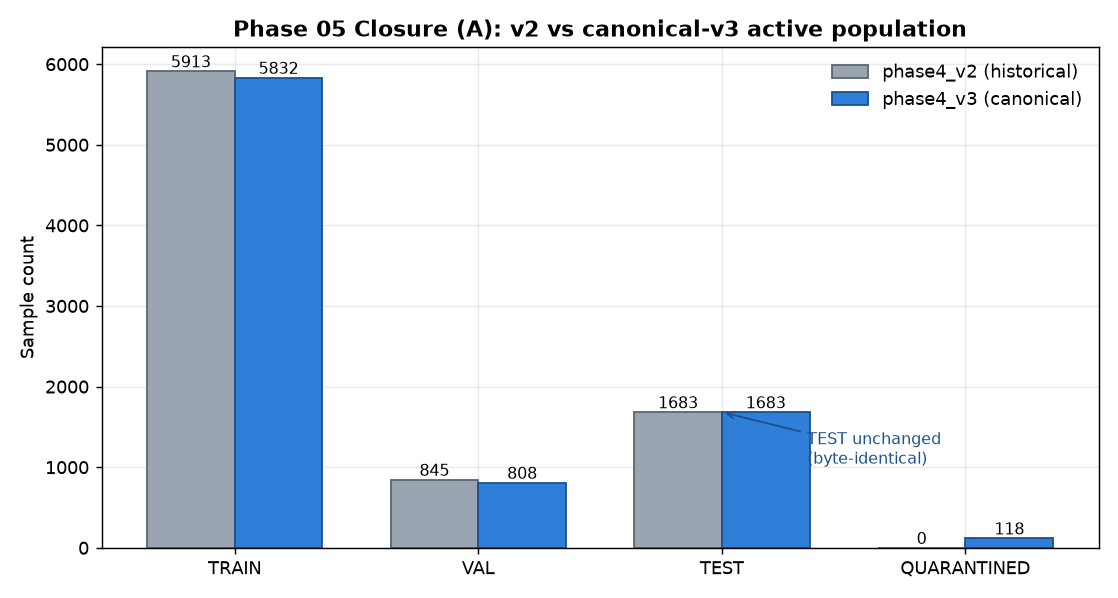

Figure A — v2 vs canonical-v3 population comparison.


In [13]:
display(Image(filename=str(FIG_DIR / 'phase05_closure_v2_vs_v3_population.png')))
print('Figure A — v2 vs canonical-v3 population comparison.')

## 13. Manifest Registry

In [14]:
registry_path = PROJECT_ROOT / 'manifests' / 'manifest_registry.json'
registry = json.loads(registry_path.read_text(encoding='utf-8'))
print('registry version          :', registry['registry_version'])
print('historical version        :', registry['historical_manifest_version'])
print('active development version:', registry['active_development_manifest_version'])
print('test membership source    :', registry['test_membership_source'])
print('quarantine count          :', registry['quarantine_count'])
print('supervisor authorized     :', registry['supervisor_authorized'])
print('promotion datetime        :', registry['promotion_datetime'])
print()
print('phase4_v2 status:', registry['phase4_v2']['status'])
print('phase4_v3 status:', registry['phase4_v3']['status'])

REGISTRY_OK = (
    registry['active_development_manifest_version'] == 'phase4_v3'
    and registry['historical_manifest_version'] == 'phase4_v2'
    and registry['quarantine_count'] == 118
    and registry['supervisor_authorized'] is True
)
print()
print('REGISTRY CONSISTENT:', REGISTRY_OK)

registry version          :

 1.0
historical version        : phase4_v2
active development version: phase4_v3
test membership source    : v2/v3 identical — TEST byte-identical in both versions
quarantine count          : 118
supervisor authorized     : True
promotion datetime        : 2026-09-19T19:03:33.820707Z

phase4_v2 status: HISTORICAL_SUPERSEDED_FOR_FUTURE_DEVELOPMENT
phase4_v3 status: CANONICAL_ACTIVE_DEVELOPMENT

REGISTRY CONSISTENT: True


## 14. Manifest Guard — Version-Aware Validation

The guard now supports explicit version selection so historical scripts cannot silently reinterpret their input as v3.

In [15]:
from src.utils.manifest_guard import (
    validate_manifest_version,
    get_canonical_hash,
)

res_v2 = validate_manifest_version('phase4_v2')
res_v3 = validate_manifest_version('phase4_v3')
print('GUARD v2 :', 'PASS' if res_v2['ok'] else 'FAIL', '| files:', sorted(res_v2['passed']))
print('GUARD v3 :', 'PASS' if res_v3['ok'] else 'FAIL', '| files:', sorted(res_v3['passed']))
print()
print('get_canonical_hash v2/test :', get_canonical_hash('phase4_v2', 'test'))
print('get_canonical_hash v3/test :', get_canonical_hash('phase4_v3', 'test'))
GUARD_OK = res_v2['ok'] and res_v3['ok']
quarantine_recognised = 'quarantined' in res_v3['passed']
print('v3 quarantine file recognised by guard:', quarantine_recognised)

GUARD v2 : PASS | files: ['all_paired', 'test', 'train', 'val']
GUARD v3 : PASS | files: ['all_paired', 'duplicate_groups', 'grouping_provenance', 'quarantined', 'test', 'train', 'val']

get_canonical_hash v2/test : 9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727
get_canonical_hash v3/test : 9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727
v3 quarantine file recognised by guard: True


## 15. Historical-v2 vs Future-clean-v3 Interpretation

Two status dimensions are maintained side by side. This prevents history from being confused with the clean branch.

| Phase | Historical v2 scientific status | Clean-v3 revalidation status |
|---|---|---|
| 06 | COMPLETE (v2 evidence) | RERUN_REQUIRED (descriptive refresh) |
| 07 | COMPLETE (v2 evidence) | RERUN_REQUIRED (taxonomy/population refresh) |
| 08 | COMPLETE (v2 evidence) | PARTIAL_RERUN_REQUIRED (infrastructure verification) |
| 09 | COMPLETE / v2 CONTAMINATED | REVALIDATION_REQUIRED (clean training + VAL selection) |
| 10 | COMPLETE / v2 CONTAMINATED | REVALIDATION_REQUIRED |
| 11 | COMPLETE / v2 CONTAMINATED | REVALIDATION_REQUIRED |
| 12 | COMPLETE / v2 CONTAMINATED | REVALIDATION_REQUIRED |
| 13 | COMPLETE / v2 CONTAMINATED | REVALIDATION_REQUIRED |
| 14 | COMPLETE / FROZEN DIAGNOSTIC | REVALIDATION_REQUIRED |
| 15 | COMPLETE / v2 CONTAMINATED | REVALIDATION_REQUIRED (protocol -> clean v3) |

**No historical result may be silently presented as a v3 result.**

In [16]:
redir_scope_path = PROJECT_ROOT / 'reports' / 'tables' / 'phase05_clean_rerun_scope.csv'
scope = pd.read_csv(redir_scope_path)
display(scope[['phase', 'phase_name', 'historical_v2_status', 'clean_v3_status', 'rerun_type']])
RERUN_SCOPE_OK = len(scope) == 10 and (scope['clean_v3_status'] != 'COMPLETE').all()
print('Clean rerun scope covers Phases 06-15 and none marked COMPLETE:', RERUN_SCOPE_OK)

,phase,phase_name,historical_v2_status,clean_v3_status,rerun_type
0,6,Descriptive Dataset Analysis,COMPLETE,RERUN_REQUIRED,descriptive_data_dependent_refresh
1,7,Taxonomy and Labeling,COMPLETE,RERUN_REQUIRED,taxonomy_population_refresh
2,8,Infrastructure Verification,COMPLETE,PARTIAL_RERUN_REQUIRED,infrastructure_verification
3,9,Baseline Model Training,COMPLETE_v2_CONTAMINATED,RERUN_REQUIRED,clean_training_and_val_checkpoint_selection
4,10,Baseline Comparison,COMPLETE_v2_CONTAMINATED,RERUN_REQUIRED,clean_baseline_training_comparison
5,11,Failure Analysis,COMPLETE_v2_CONTAMINATED,RERUN_REQUIRED,clean_failure_analysis
6,12,Oracle Evaluation,COMPLETE_v2_CONTAMINATED,RERUN_REQUIRED,clean_oracle_evaluation
7,13,Localizer Training,COMPLETE_v2_CONTAMINATED,RERUN_REQUIRED,clean_localizer_training_and_evaluation
8,14,Regional Refiner Training,COMPLETE_v2_CONTAMINATED,RERUN_REQUIRED,clean_regional_refiner_training_checkpoint_evaluation
9,15,Regional Refiner Protocol,COMPLETE_v2_CONTAMINATED,REVALIDATION_REQUIRED,clean_v3_protocol_revalidation


Clean rerun scope covers Phases 06-15 and none marked COMPLETE: True


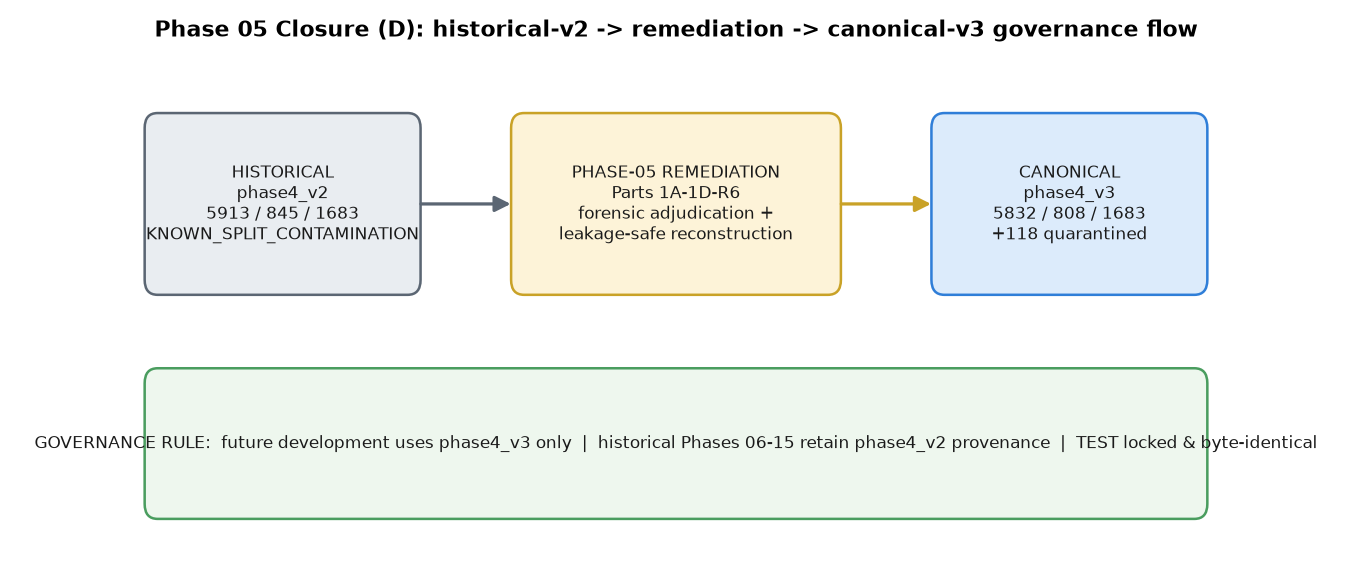

Figure D — historical-v2 -> remediation -> canonical-v3 governance flow.


In [17]:
display(Image(filename=str(FIG_DIR / 'phase05_closure_governance_flow.png')))
print('Figure D — historical-v2 -> remediation -> canonical-v3 governance flow.')

## 16. Required Clean Rerun Scope

All future scientific development uses `phase4_v3` only. Before the main four-domain Phase 19+ work, the required clean reruns must be completed. **None are executed here.**

**Phase-14 distinction preserved:** the historical regional-refiner *training* used A3 GT-derived positives + perturbed positives + negatives — **not** Stage-4D predicted proposal crops. Historical contamination exposure arose from (a) VAL checkpoint selection on the v2 contaminated population, and (b) predicted-mode evaluation inheriting the Stage-4D proposal stream. This distinction must not be lost.

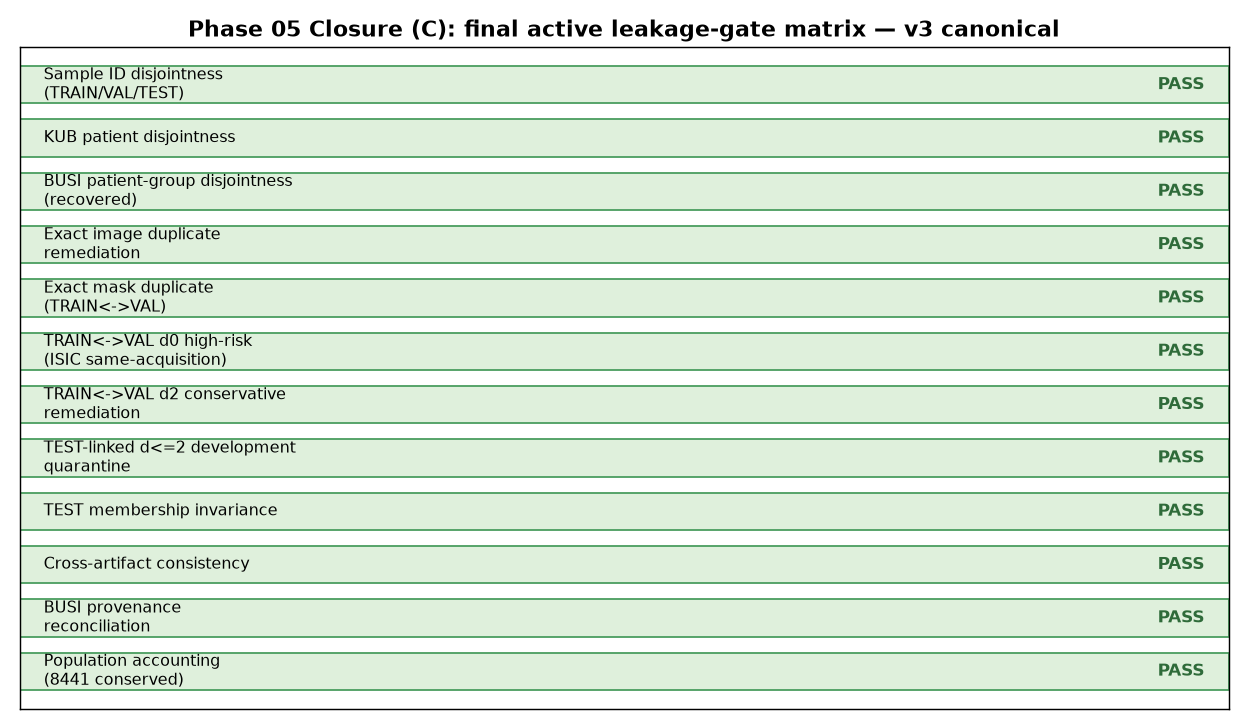

Figure C — final active leakage-gate matrix (v3 canonical).


In [18]:
display(Image(filename=str(FIG_DIR / 'phase05_closure_leakage_gate_matrix.png')))
print('Figure C — final active leakage-gate matrix (v3 canonical).')

## 17. Phase-05 Final Conclusion

In [19]:
all_checks = {
    'population_accounting_8441': POPULATION_OK,
    'dataset_breakdown_matches': BREAKDOWN_OK,
    'v2_hashes_unchanged': V2_HASHES_UNCHANGED,
    'candidate_to_canonical_byte_identical': CAND_TO_CANON_BYTE_IDENTICAL,
    'promoted_hashes_match_brief': PROMOTED_HASHES_OK,
    'test_byte_identical': TEST_BYTE_IDENTICAL,
    'busi_mapping_sha_matches': BUSI_MAPPING_OK,
    'kub_exact_duplicate_resolved': KUB_EXACT_DUPLICATE_OK,
    'registry_consistent': REGISTRY_OK,
    'guard_v2_and_v3_pass': GUARD_OK,
    'rerun_scope_defined': RERUN_SCOPE_OK,
    'no_test_content_read': (GOVERNANCE['test_image_reads'] == 0 and GOVERNANCE['test_mask_reads'] == 0),
}
chk_df = pd.DataFrame({'check': list(all_checks.keys()),
                       'result': ['PASS' if v else 'FAIL' for v in all_checks.values()]})
display(chk_df)
PHASE05_GATE_PASS = all(all_checks.values())
print('PHASE-05 SCIENTIFIC GATE:', 'PASS' if PHASE05_GATE_PASS else 'FAIL')

,check,result
0,population_accounting_8441,PASS
1,dataset_breakdown_matches,PASS
2,v2_hashes_unchanged,PASS
3,candidate_to_canonical_byte_identical,PASS
4,promoted_hashes_match_brief,PASS
5,test_byte_identical,PASS
6,busi_mapping_sha_matches,PASS
7,kub_exact_duplicate_resolved,PASS
8,registry_consistent,PASS
9,guard_v2_and_v3_pass,PASS


PHASE-05 SCIENTIFIC GATE: PASS


### Scientific conclusion

The original v2 development split contained **verified and high-risk cross-split leakage mechanisms**. Those findings were preserved as historical evidence. A versioned leakage-safe v3 development manifest was constructed, independently audited, and promoted. **TEST membership was not changed and TEST medical content remained locked.** Future development and clean revalidation use v3. Historical v2 results remain provenance, **not** clean-v3 evidence.

This conclusion does **not** claim that all conceivable duplicate risk in the universe has been eliminated — only that the identified mechanisms were remediated conservatively and that the residual population is leakage-safe to the best available evidence.

## 18. Why Phase 06 Clean Refresh Is Next

Phase 06 (descriptive dataset analysis) is **data-population dependent**. Every population statistic, distribution, and characterisation produced under v2 describes a population that no longer corresponds to the active development split. It therefore requires a clean-v3 recomputation before any downstream scientific work.

**This notebook does NOT start Phase 06.** Phase 06 clean-v3 characterization will be separately authorized by the supervisor.

## 19. Hashes

In [20]:
# Consolidated final hash ledger
ledger = {'promoted_phase4_v3': {k: sha256_file(V3_DIR / f'{k}.csv') for k in EXPECTED_V3},
          'historical_phase4_v2': {k: sha256_file(V2_DIR / f'{k}.csv') for k in EXPECTED_V2},
          'busi_mapping': sha256_file(PROJECT_ROOT / 'reports' / 'tables' / 'phase05_busi_patient_group_mapping.csv'),
          'manifest_registry_json': sha256_file(PROJECT_ROOT / 'manifests' / 'manifest_registry.json'),
          'manifest_guard_source': sha256_file(PROJECT_ROOT / 'src' / 'utils' / 'manifest_guard.py'),
          }
print(json.dumps(ledger, indent=2))

print()
print('=' * 78)
print('PHASE-05 PART-1E CLOSURE — FINAL STATUS')
print('=' * 78)
print(f"PROMOTION AUTHORIZED                : YES")
print(f"ACTIVE DEVELOPMENT MANIFEST         : phase4_v3")
print(f"HISTORICAL MANIFEST                 : phase4_v2")
print(f"CANDIDATE -> CANONICAL BYTE IDENT   : {CAND_TO_CANON_BYTE_IDENTICAL}")
print(f"v2 HASHES UNCHANGED                 : {V2_HASHES_UNCHANGED}")
print(f"TEST BYTE IDENTICAL TO v2           : {TEST_BYTE_IDENTICAL}")
print(f"TEST CONTENT READS                  : 0")
print(f"POPULATION TRAIN/VAL/TEST/QUAR       : 5832 / 808 / 1683 / 118")
print(f"TOTAL                              : 8441")
print(f"MANIFEST GUARD v2/v3                : {'PASS' if res_v2['ok'] else 'FAIL'} / {'PASS' if res_v3['ok'] else 'FAIL'}")
print(f"PHASE05 SCIENTIFIC GATE             : {'PASS' if PHASE05_GATE_PASS else 'FAIL'}")
print(f"PHASE05 COMPLETE                    : {'YES' if PHASE05_GATE_PASS else 'NO'}")
print(f"PHASE06 STARTED                     : NO")
print(f"NEXT ACTION                         : WAIT_FOR_SUPERVISOR_PHASE06_AUTHORIZATION")
print('=' * 78)

{
  "promoted_phase4_v3": {
    "all_paired": "eb3062fa0e84f9952f994df79ed4d767417a912e18dce86560f6e2edcdd02ded",
    "train": "28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6",
    "val": "082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315",
    "test": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727",
    "quarantined": "a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c",
    "duplicate_groups": "830d3c0ce08f735081e5a44fe3a740031da1c70cfc19ebcb4ef89c31acd704fb",
    "grouping_provenance": "3eff84851d33e1c8b5894ce05049433287067a5e6088a90f5c67394230317f66"
  },
  "historical_phase4_v2": {
    "all_paired": "66350d465209e4bf0948a16f0da213abb9f8f87c0b222ead7632d2350463f7cc",
    "train": "d67b549a6cc80b579dfaf4976b9b51630f6d703d8c6bfb33188355cfa6056bc3",
    "val": "46079b594ed9535c2de953bb976684b8b0bab30c27c6e6e4f2b9f9314b4cc5f4",
    "test": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727"
  },
  "busi_ma